# Step 3e: Device 1, TCAD against the model

Sheet density n under the gate against V_GS, at V_DS = 0.

- **TCAD [TCAD]:** run n16. Sentaurus averaged the electron density in a box under the gate (0.1 µm deep). Average × 0.1 µm = sheet density n in cm⁻².
- **Model [P]:** `gate.py` with Device 1 inputs from `device1.py` (V_OFF and C_g″).
- We compare three numbers: where n reaches 1e11 cm⁻² (turn-on), the ON slope dn/dV_GS, and the subthreshold swing.

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt
import device1 as d1
from gate import n_exact, n_total, Q, EPS0

def read_plt(filename):
    """Read a Sentaurus .plt text file into a dictionary {column name: numpy array}."""
    with open(filename) as f:
        text = f.read()
    names = re.findall(r'"([^"]+)"', text.split("functions")[0])
    values = np.array(text.split("Data {")[1].rsplit("}", 1)[0].split(), dtype=float)
    return {name: values[i::len(names)] for i, name in enumerate(names)}

plt_data = read_plt("tcad_data/device1_n16_gate_sweep_des.plt")
Vg_all = plt_data["gate OuterVoltage"]
n_all = plt_data["AveWindow((-1.12,1.1),(-1.02,1.6)) eDensity"] * 1e-5   # cm^-3 x 0.1 um = cm^-2

start = np.argmin(Vg_all)            # ramp 1 goes 0 -> -3 V; ramp 2 (-3 -> +1 V) starts here
Vg_tcad, n_tcad = Vg_all[start:], n_all[start:]
print(f"TCAD: {len(Vg_tcad)} points from {Vg_tcad[0]:+.2f} V to {Vg_tcad[-1]:+.2f} V")

TCAD: 86 points from -3.00 V to +1.00 V


In [2]:
voff_paper = d1.v_off()                                   # paper polarization
voff_tcadP = d1.v_off(vt=d1.v_total() * 3.41 / 3.16)      # polarization scaled to the TCAD value

V = np.linspace(-2.0, 1.0, 301)
n_ex_paper = np.array([n_exact(v, voff_paper, d1.U)[0] for v in V])
n_ex_tcadP = np.array([n_exact(v, voff_tcadP, d1.U)[0] for v in V])
n_cm = n_total(V, v_off=voff_tcadP, u=d1.U)                # compact Eq. (15), gamma = 0.55
print(f"V_OFF = {voff_paper:+.3f} V (paper polarization),  {voff_tcadP:+.3f} V (TCAD polarization)")
print(f"C_g'' = {d1.CG:.3e} F/cm^2,  u = C_g''/q = {d1.U:.3e} cm^-2 per V")

V_OFF = -0.988 V (paper polarization),  -1.260 V (TCAD polarization)
C_g'' = 4.206e-07 F/cm^2,  u = C_g''/q = 2.625e+12 cm^-2 per V


In [3]:
def turn_on(Vx, nx, level=1e11):
    """Gate voltage where n crosses `level` (interpolated on a log scale)."""
    return np.interp(np.log10(level), np.log10(nx), Vx)

def on_slope(Vx, nx):
    """dn/dV_GS from a straight-line fit between -0.5 and +0.9 V."""
    m = (Vx > -0.5) & (Vx < 0.9)
    return np.polyfit(Vx[m], nx[m], 1)[0]

def swing(Vx, nx):
    """Subthreshold swing in mV per decade, fitted where 1e3 < n < 1e10."""
    m = (nx > 1e3) & (nx < 1e10)
    return 1000.0 / np.polyfit(Vx[m], np.log10(nx[m]), 1)[0]

rows = [("TCAD n16", Vg_tcad, n_tcad),
        (f"exact model, V_OFF {voff_paper:+.2f}", V, n_ex_paper),
        (f"exact model, V_OFF {voff_tcadP:+.2f}", V, n_ex_tcadP),
        (f"compact model, V_OFF {voff_tcadP:+.2f}", V, n_cm)]
print(f"{'':30s}{'V at 1e11':>10s}{'ON slope':>12s}{'d_eff':>8s}{'swing':>9s}")
print(f"{'':30s}{'(V)':>10s}{'(cm^-2/V)':>12s}{'(nm)':>8s}{'(mV/dec)':>9s}")
for name, Vx, nx in rows:
    s = on_slope(Vx, nx)
    d_eff = d1.EPS_R * EPS0 / (Q * s) * 1e7                # cm -> nm: thickness that gives this slope
    print(f"{name:30s}{turn_on(Vx, nx):+10.3f}{s:12.3e}{d_eff:8.1f}{swing(Vx, nx):9.1f}")

                               V at 1e11    ON slope   d_eff    swing
                                     (V)   (cm^-2/V)    (nm) (mV/dec)
TCAD n16                          -1.188   3.068e+12    17.1     67.1
exact model, V_OFF -0.99          -1.063   2.478e+12    21.2     89.5
exact model, V_OFF -1.26          -1.335   2.491e+12    21.1     89.5
compact model, V_OFF -1.26        -1.387   2.440e+12    21.5    108.3


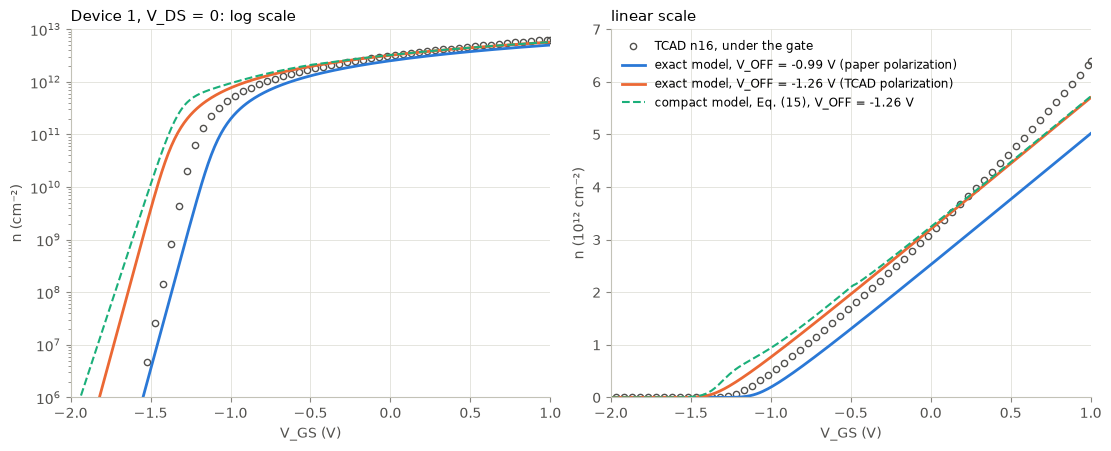

In [4]:
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED,
                     "xtick.labelcolor": INK, "ytick.labelcolor": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, scale in ((ax1, 1.0), (ax2, 1e12)):
    draw = ax.semilogy if scale == 1.0 else ax.plot
    draw(Vg_tcad, n_tcad / scale, "o", mfc="none", mec=INK, ms=4.5, label="TCAD n16, under the gate")
    draw(V, n_ex_paper / scale, color=BLUE, lw=2, label=f"exact model, V_OFF = {voff_paper:+.2f} V (paper polarization)")
    draw(V, n_ex_tcadP / scale, color=ORANGE, lw=2, label=f"exact model, V_OFF = {voff_tcadP:+.2f} V (TCAD polarization)")
    draw(V, n_cm / scale, color=AQUA, lw=1.5, ls="--", label=f"compact model, Eq. (15), V_OFF = {voff_tcadP:+.2f} V")
    ax.set_xlim(-2, 1)
    ax.set_xlabel("V_GS (V)")
    ax.grid(True, color=GRID, lw=0.6)
ax1.set_ylim(1e6, 1e13); ax1.set_ylabel("n (cm⁻²)")
ax2.set_ylim(0, 7);      ax2.set_ylabel("n (10¹² cm⁻²)")
ax1.set_title("Device 1, V_DS = 0: log scale", loc="left", fontsize=11)
ax2.set_title("linear scale", loc="left", fontsize=11)
ax2.legend(loc="upper left", fontsize=8.5)
fig.savefig("figures/step3e_tcad_vs_model.png", dpi=200)
plt.show()